# Herbaceous vegetation: clean, join and check the ODK data

This notebook answers vegetation question 1: a data quality report for the project. The code is in `src/vegetation/`. The report is `reports/03_vegetation_data_quality_report.md`.

Errors are flagged, never fixed. Every check returns a list of flags. No recorded value is changed or removed.

**Where the code is.**

1. `load.py`: read the files as delivered.
2. `model.py`: clean and join the tables.
3. `checks.py` with `config/veg_qaqc_checks.yaml`: the checks.
4. `summaries.py`: survey, plot and effort tables.
5. `mapping.py` and `plots.py`: maps and figures.

## Setup

Find the folder of the repository and add its `src` folder to the Python path, so the project packages import in any Jupyter kernel.

In [7]:
import sys
from pathlib import Path

ROOT = next(
    p
    for p in [Path.cwd(), *Path.cwd().parents]
    if (p / "pyproject.toml").exists()
)
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))

Import the libraries and the project code. Set how wide tables can be, and create the folder for the figures.

In [10]:
import matplotlib.pyplot as plt
import pandas as pd

from common.paths import FIGURES, OUTPUTS
from vegetation import cli, mapping, plots, report, summaries

pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 40)
pd.set_option("display.max_colwidth", 90)
FIGURES.mkdir(parents=True, exist_ok=True)

Run the whole process with one call. `cli.run()` reads the files, joins them, runs all checks and builds the summaries. The output shows the size of each joined table.

In [11]:
res = cli.run()
m, flags = res["model"], res["flags"]
{k: v.shape for k, v in m.items() if k != "raw"}

/Users/eugeinzaugarat/EugeFiles/Insight Delta/Clientes/Natural State/Entrevista/analyzing_birds_diversity_ODK/src/vegetation/model.py:387: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  rec["is_unknown"] = rec["is_unknown"].fillna(False).astype(bool)


{'plots': (51, 47),
 'surveys': (32, 38),
 'quadrats': (640, 24),
 'species_records': (2243, 22)}

## Joining the tables

The tables are linked as follows:

1. Survey `KEY` to quadrat `PARENT_KEY`.
2. Quadrat `KEY` to additional species `PARENT_KEY`.
3. Survey plot id to the vegplot entity, then to the centroid and its
   registration.
4. Species ids in each quadrat to the species list.

Check that every join found its partner. Each line shows the number of rows that were linked and the total number of rows.

In [12]:
s, q = m["surveys"], m["quadrats"]
r, p = m["species_records"], m["plots"]
added = r["source"] == "additional_species"
listed = r["source"] == "species_list"
checks = {
    "surveys linked to a vegplot entity": (
        s["centroid_uuid"].notna().sum(),
        len(s),
    ),
    "quadrats linked to a survey": (
        q["survey_key"].isin(s["survey_key"]).sum(),
        len(q),
    ),
    "additional rows linked to a quadrat": (
        r.loc[added, "quadrat_key"].isin(q["quadrat_key"]).sum(),
        added.sum(),
    ),
    "listed species ids found in the list": (
        r.loc[listed, "taxon_name"].notna().sum(),
        listed.sum(),
    ),
    "additional rows with a taxon name": (
        r.loc[added, "taxon_name"].notna().sum(),
        added.sum(),
    ),
}
pd.DataFrame(checks, index=["linked", "total"]).T

,linked,total
surveys linked to a vegplot entity,32,32
quadrats linked to a survey,640,640
additional rows linked to a quadrat,1296,1296
listed species ids found in the list,947,947
additional rows with a taxon name,1295,1296


Every survey, quadrat and species id is linked. One additional species row has no species name.

## Overview of the flags

We set one row for each check: level, severity, description, the number of flags and the number of plots affected.

In [13]:
cat = res["catalogue"].set_index("id")
counts = flags.groupby("check_id").agg(
    flags=("entity_key", "size"), plots=("plot_name", "nunique")
)
overview = cat[["level", "severity", "name", "description"]].join(counts)
overview[["flags", "plots"]] = (
    overview[["flags", "plots"]].fillna(0).astype(int)
)
overview

,level,severity,name,description,flags,plots
id,,,,,,
D01,project,error,stratum_not_sampled,A design stratum has no registered plot,1,0
D02,project,warning,primary_plot_not_registered,Primary (planned) plot has not been registered,6,6
P01,plot,info,plot_not_viable,Plot registered as not viable,1,1
P02,plot,error,not_viable_without_reason,Plot marked not viable without a reason,0,0
P03,plot,error,multiple_registrations,"Centroid registered more than once, or several vegplot entities",0,0
P04,plot,error,midpoint_too_far_from_centroid,Registered midpoint more than 25 m from the prescribed centroid,1,1
P05,plot,warning,transect_length_off,"Length from A to B differs from 50 m, or a half from 25 m, by more than the tolerance",11,11
P06,plot,warning,transect_not_north_south,Transect bearing is further from the north/south axis than the tolerance,30,30
P07,plot,warning,transect_not_straight,Midpoint is off the line from A to B by more than the tolerance,14,14


Count the flags by level and severity.

In [14]:
flags.pivot_table(
    index="level",
    columns="severity",
    values="check_id",
    aggfunc="size",
    fill_value=0,
)

severity,error,info,warning
level,,,
plot,1,1,55
project,1,0,6
quadrat,10,16,140
record,1,342,165
survey,2,32,37


There are 809 flags: 15 errors, 403 warnings and 391 info. Most info flags are unknown species that still wait for an identification.

## Survey level summary

We set one row for each submission: 
- `quadrats_with_species` is computed from the records
- `quadrats_with_species_reported` is the number the form saved

In [15]:
ss = res["survey_summary"]
cols = [
    "plot_name",
    "survey_date",
    "recorder",
    "duration_min",
    "review_state",
    "n_quadrats",
    "quadrats_with_species",
    "quadrats_with_species_reported",
    "richness",
    "unknown_morphospecies",
    "mean_species_per_quadrat",
    "median_gps_accuracy_m",
    "median_offset_from_line_m",
    "n_error",
    "n_warning",
    "n_info",
    "status",
]
ss[cols].round(1)

,plot_name,survey_date,recorder,duration_min,review_state,n_quadrats,quadrats_with_species,quadrats_with_species_reported,richness,unknown_morphospecies,mean_species_per_quadrat,median_gps_accuracy_m,median_offset_from_line_m,n_error,n_warning,n_info,status
0,SavMon_LW_Plot_01,2026-05-23,Grace,69.6,,20,20,19,31,7,4.4,3.7,9.8,0,18,11,Warning
1,SavMon_LW_Plot_02,2026-05-24,Grace,100.3,,20,19,17,18,6,2.6,2.4,1.7,0,2,9,Warning
2,SavMon_LW_Plot_03,2026-05-20,Sam,58.7,,20,18,18,15,8,2.4,4.3,5.6,0,8,26,Warning
3,SavMon_LW_Plot_04,2026-05-25,Grace,56.4,,20,19,18,20,12,2.7,3.0,3.9,0,14,13,Warning
4,SavMon_LW_Plot_05,2026-05-22,Grace,102.5,,20,19,12,16,3,2.3,2.8,21.0,0,24,5,Warning
5,SavMon_LW_Plot_06,2026-05-23,Grace,91.8,,20,20,20,24,10,4.0,3.0,4.9,0,12,15,Warning
6,SavMon_LW_Plot_07,2026-05-24,Grace,56.5,,20,20,17,18,10,3.8,3.4,10.2,0,8,24,Warning
7,SavMon_LW_Plot_08,2026-05-19,Sam,236.0,,20,20,19,26,10,5.2,4.9,7.4,0,11,16,Warning
8,SavMon_LW_Plot_09,2026-05-21,Grace,81.7,,20,20,19,27,8,4.5,3.8,6.5,0,14,6,Warning
9,SavMon_LW_Plot_10,2026-05-21,Grace,63.2,,20,20,18,21,4,3.4,2.8,3.6,1,2,11,Error


Count the survey status in the analysis set, which leaves out the rejected submissions.

In [16]:
ss.loc[ss["in_analysis_set"], "status"].value_counts()

status
Warning    21
Error       8
OK          1
Name: count, dtype: int64

Of 30 surveys, 1 is OK, 21 have warnings and 8 have errors. The two rejected submissions are second surveys of plots 18 and 21. The form summary of quadrats with species is often wrong.

## Plot level summary

We set one row for each prescribed location. Diversity comes from the accepted survey:
- `sample_coverage` shows how complete the list of taxa in the plot is likely to be.

In [17]:
ps = res["plot_summary"]
cols = [
    "plot_name",
    "stratum_label",
    "design_status",
    "registered",
    "is_viable",
    "n_surveys",
    "mid_to_centroid_m",
    "len_a_b_m",
    "bearing_a_b_deg",
    "richness",
    "chao2_richness",
    "sample_coverage",
    "mean_species_per_quadrat",
    "hill_N1",
    "top_taxon",
    "top_taxon_frequency",
    "n_error",
    "n_warning",
    "status",
]
ps[cols].round(2)

,plot_name,stratum_label,design_status,registered,is_viable,n_surveys,mid_to_centroid_m,len_a_b_m,bearing_a_b_deg,richness,chao2_richness,sample_coverage,mean_species_per_quadrat,hill_N1,top_taxon,top_taxon_frequency,n_error,n_warning,status
0,SavMon_LW_Plot_01,savanna,primary,True,yes,1,11.41,63.25,130.69,31.0,43.47,0.84,4.45,21.38,tephrosia purpurea,0.45,0,20,Warning
1,SavMon_LW_Plot_02,savanna,primary,True,yes,1,13.29,53.85,102.67,18.0,20.85,0.89,2.63,14.61,herb_017,0.40,0,4,Warning
2,SavMon_LW_Plot_03,savanna,primary,True,yes,1,5.31,57.47,106.92,15.0,19.99,0.84,2.39,10.68,herb_038,0.40,0,10,Warning
3,SavMon_LW_Plot_04,savanna,primary,True,yes,1,5.70,53.45,109.54,20.0,25.70,0.84,2.74,14.95,portulaca kermesina,0.40,0,15,Warning
4,SavMon_LW_Plot_05,savanna,primary,True,yes,1,19.98,45.98,116.62,16.0,24.55,0.80,2.26,10.25,eragrostis trichophora,0.60,0,26,Warning
5,SavMon_LW_Plot_06,savanna,primary,True,yes,1,4.31,48.42,106.15,24.0,28.28,0.89,3.95,16.46,hibiscus micranthus,0.65,0,13,Warning
6,SavMon_LW_Plot_07,savanna,primary,True,yes,1,5.94,52.32,85.33,18.0,19.58,0.94,3.75,12.07,commelina benghalensis,0.75,0,10,Warning
7,SavMon_LW_Plot_08,savanna,primary,True,yes,1,5.65,47.58,111.93,26.0,28.96,0.93,5.15,16.19,eragrostis rigidior,0.95,0,13,Warning
8,SavMon_LW_Plot_09,savanna,primary,True,yes,1,5.35,45.72,77.93,27.0,45.52,0.86,4.50,18.65,indigofera schimperi,0.55,0,15,Warning
9,SavMon_LW_Plot_10,savanna,primary,True,yes,1,10.16,57.49,109.17,21.0,47.12,0.84,3.40,13.12,indigofera schimperi,0.80,1,3,Error


31 plots are registered and 20 are not. Plot 23 is not viable (private property) and backup plot 46 was used. The midpoint of plot 14 is 34 m from the centroid. The SOP allows 25 m.

## Sampling effort

Count planned, registered, viable and surveyed plots for each stratum and design status.

In [18]:
res["design_coverage"]

,stratum_label,design_status,planned,registered,viable,surveyed
0,savanna,backup,10,1,1,1
1,savanna,primary,30,30,29,29
2,shrubland,backup,5,0,0,0
3,shrubland,primary,6,0,0,0


No shrubland plot was registered, so the project has no data for this stratum. In the savanna, 29 of 30 primary plots and one backup plot were surveyed.

Check that each quadrat has a photo, a GPS point with good accuracy and an answer to the question about herbs.

In [19]:
res["field_completeness"]

,item,count,expected,completeness
0,quadrats recorded,600,600,1.0
1,quadrat photos,600,600,1.0
2,quadrat GPS points,600,600,1.0
3,GPS accuracy <= 5 m,600,600,1.0
4,herbs_present answered,600,600,1.0


Show the number of surveys and the hours spent in plots for each day and recorder.

In [20]:
res["daily_effort"].round(1)

,survey_date,recorder,surveys,rejected,hours
0,2026-05-19,Sam,1,0,3.9
1,2026-05-20,Sam,3,0,4.9
2,2026-05-21,Grace,4,0,5.1
3,2026-05-22,Grace,5,0,6.2
4,2026-05-23,Grace,5,0,5.7
5,2026-05-24,Grace,5,0,5.2
6,2026-05-25,Grace,2,0,2.0
7,2026-05-26,Grace,4,1,3.3
8,2026-05-26,Sam,2,1,1.1
9,2026-05-27,Grace,1,0,0.9


Field work is complete: every quadrat has a photo and an accurate GPS point. Two recorders did all surveys in 9 days, mostly 4 or 5 plots a day.

Draw species accumulation. 

- Left: how the number of taxa grows with the quadrats inside each plot.
- Right: how it grows with the number of plots, with the Chao2 estimate of the total.

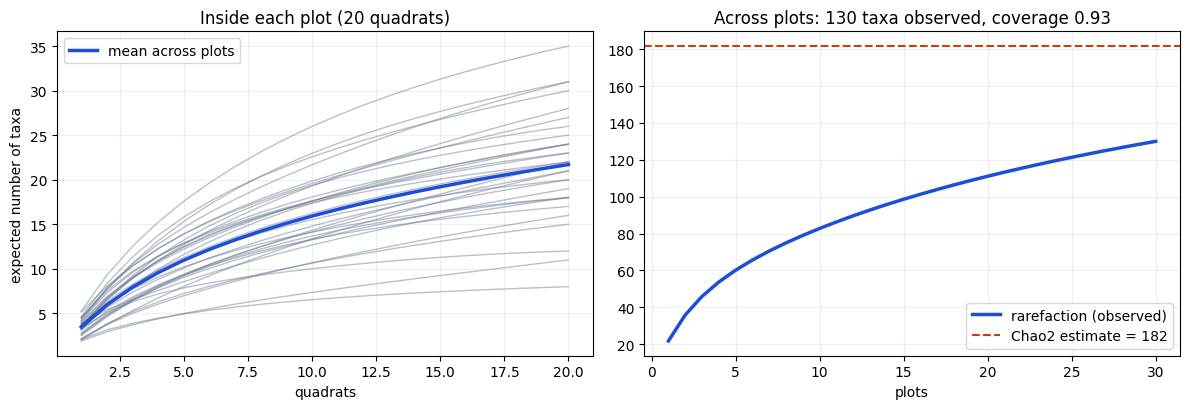

{'S_obs': 130,
 'chao2': 181.6727272727273,
 'coverage': np.float64(0.9268920100838607),
 'Q1': 49,
 'Q2': 21,
 'T': 30}

In [21]:
fig = plots.accumulation_figure(m, FIGURES / "veg_species_accumulation.png")
plt.show()
curve, ch = summaries.project_accumulation(m)
ch

Are 20 quadrats enough in a plot? Compare the taxa expected with 10, 15 and 20 quadrats.

In [22]:
acc = summaries.plot_accumulation(m).pivot(
    index="plot_name", columns="units", values="expected_richness"
)
pd.DataFrame(
    {
        "taxa_at_10": acc[10],
        "taxa_at_20": acc[20],
        "share_found_by_10": acc[10] / acc[20],
        "gain_last_5_quadrats": acc[20] - acc[15],
    }
).describe().round(2)

,taxa_at_10,taxa_at_20,share_found_by_10,gain_last_5_quadrats
count,30.00,30.00,30.00,30.00
mean,15.92,21.70,0.74,2.49
std,4.53,6.12,0.05,0.88
min,6.54,8.00,0.64,0.57
25%,13.32,18.00,0.70,1.92
50%,15.87,22.00,0.74,2.46
75%,18.99,24.75,0.77,3.16
max,25.98,35.00,0.83,4.13


Summarise sample coverage and the Chao2 estimate in the plots with a survey.

In [23]:
ok = ps[ps["richness"].notna()]
cov = ok["sample_coverage"]
gap = (ok["chao2_richness"] > 1.5 * ok["richness"]).sum()
print(f"plot coverage: median {cov.median():.2f}, lowest {cov.min():.2f}")
print(f"plots with coverage below 0.90: {(cov < 0.9).sum()}")
print(f"plots where Chao2 is more than 1.5 times observed: {gap}")

plot coverage: median 0.88, lowest 0.69
plots with coverage below 0.90: 20
plots where Chao2 is more than 1.5 times observed: 10


The curves do not flatten. The last 5 quadrats still add about 2.5 taxa, and the median coverage is 0.88. Twenty quadrats give a fair but incomplete list of taxa for each plot.

## Identification quality

List the taxa by how many quadrats they were found in. `is_unknown` marks placeholder morphospecies such as `herb_017`.

In [24]:
tf = res["taxon_frequency"]
used = r["survey_key"].isin(summaries.analysis_surveys(m)["survey_key"])
print(f"{len(tf)} taxa; {tf['is_unknown'].sum()} are unidentified")
print("records by source:", r.loc[used, "source"].value_counts().to_dict())
tf.head(20)

130 taxa; 60 are unidentified
records by source: {'additional_species': 1204, 'species_list': 889}


,taxon,source,is_unknown,plots,quadrats,plot_frequency
0,Indigofera schimperi,species_list,False,18,120,0.600000
1,Tephrosia purpurea,additional_species,False,21,100,0.700000
2,herb_017,additional_species,True,13,88,0.433333
3,herb_016,additional_species,True,16,84,0.533333
4,Hibiscus micranthus,species_list,False,22,83,0.733333
5,herb_010,additional_species,True,13,83,0.433333
6,Commelina benghalensis,species_list,False,21,81,0.700000
7,Eragrostis rigidior,species_list,False,13,69,0.433333
8,Aristida adscensionis,species_list,False,18,68,0.600000
9,Rhynchosia totta,additional_species,False,17,65,0.566667


Show the flags about names: not canonical, already in the list, possible misspelling, several placeholders and notes from later identification.

In [25]:
naming = flags[flags["check_id"].isin(["R05", "R06", "R07", "R08", "R10"])]
by_name = naming.groupby(["check_id", "value"]).size().rename("records")
by_name.reset_index().head(40)

,check_id,value,records
0,R05,'Evolvulus alsinoides ',66
1,R05,'Justicia divaricata ',1
2,R06,Pechuel-loeschea leubnitziae,4
3,R07,Ipomea leucanthemum,2
4,R07,Ipomea sinensis,2
5,R08,Aristida scabrivalvis,56
6,R08,Justicia divaricata,2
7,R10,herb_033,3
8,R10,herb_039,4
9,R10,herb_058,2


60 of 130 taxa are unidentified, and three of the most frequent taxa are placeholders. Typed names have extra spaces, spelling errors and duplicates. Richness is therefore an upper limit.

## Maps of transect locations

Draw all prescribed locations, coloured by state. Squares are backup locations. Rings mark a stratum that was never registered.

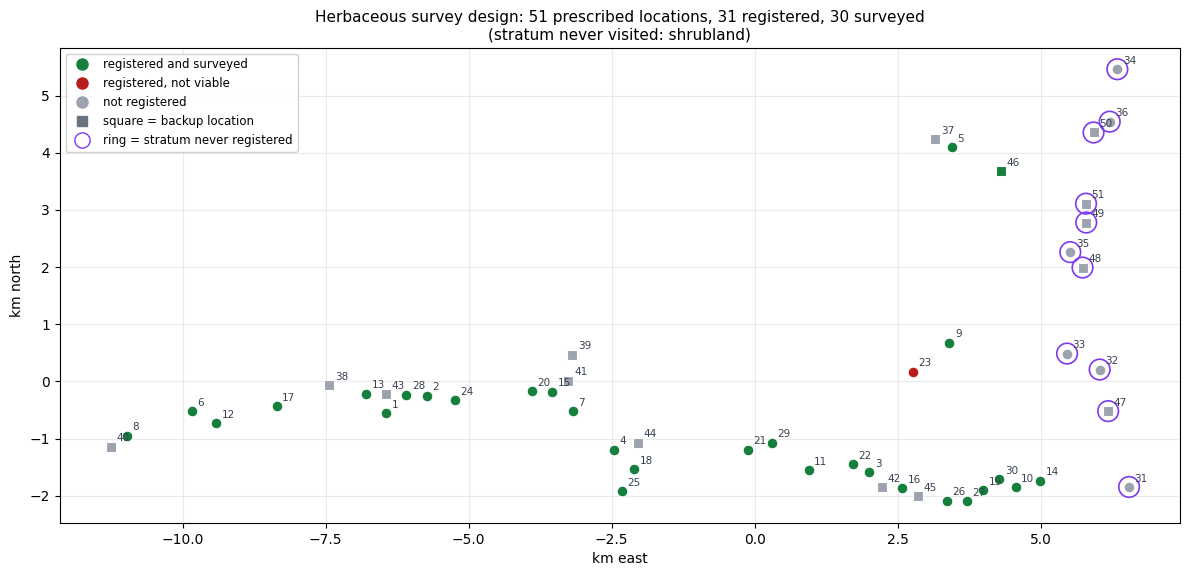

In [26]:
fig = mapping.overview_map(m, FIGURES / "veg_map_overview.png")
plt.show()

Draw four plots in detail, in metres around the prescribed centroid: the registered transect and belt, the 25 m limit, the north/south axis and the
quadrats. Red quadrats have a position flag.

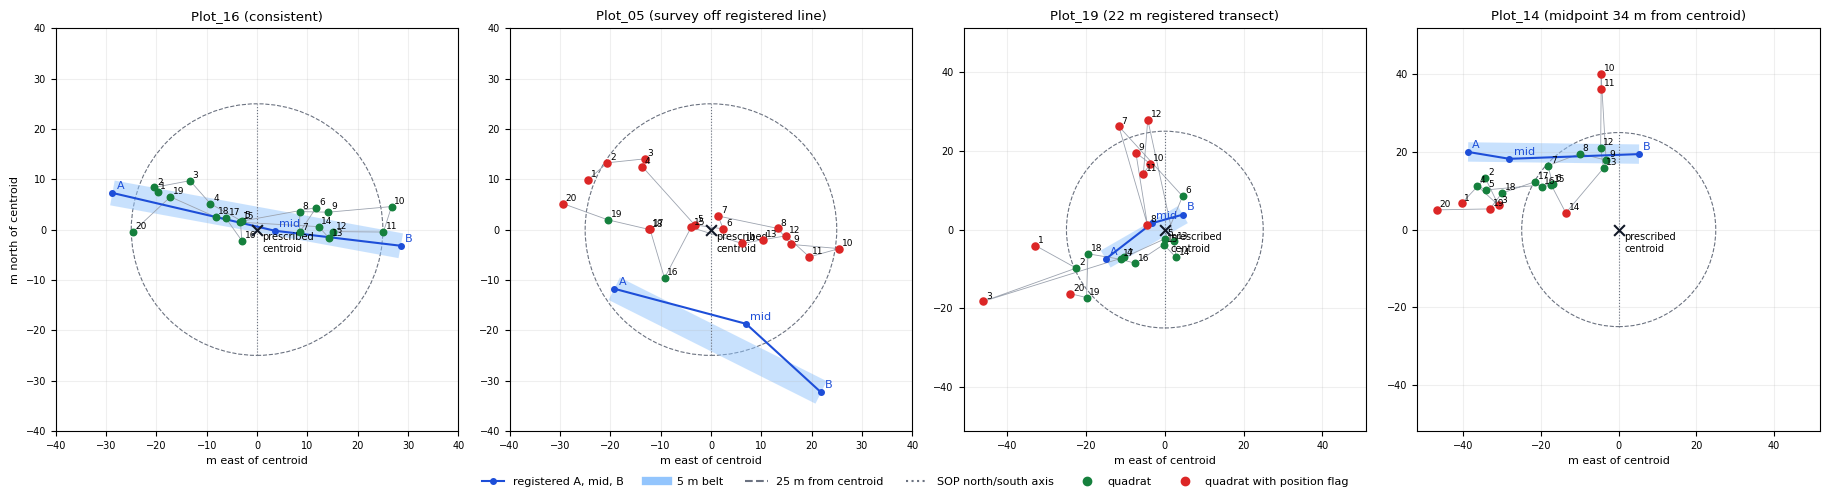

In [27]:
fig = mapping.detail_panels(
    m, flags, cli.DETAIL_PLOTS, FIGURES / "veg_map_plot_details.png"
)
plt.show()

Draw the direction of every registered transect. The green bands show the allowed angle around north/south.

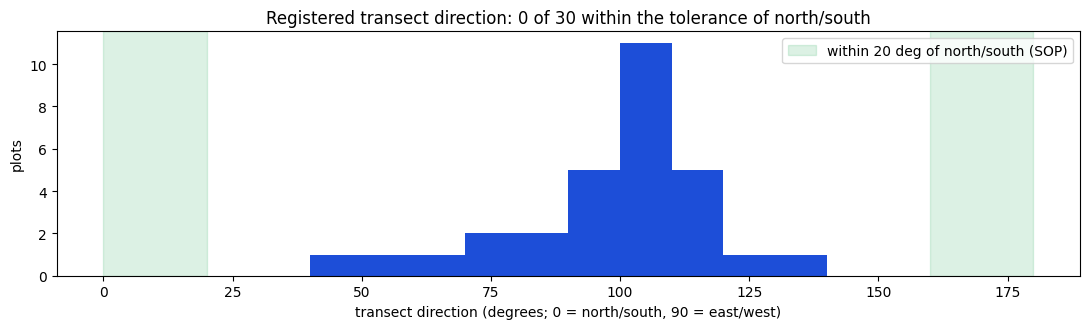

In [28]:
fig = plots.bearing_figure(m, path=FIGURES / "veg_transect_bearings.png")
plt.show()

Every registered transect runs roughly east to west, while the SOP asks for north to south. Since it happens in every plot, it is most likely a field method issue, not a GPS error.

Build the interactive map: centroids, transects and quadrats on a satellite image. Each layer can be switched on and off.

In [29]:
mapping.interactive_map(m, flags, FIGURES / "veg_map_interactive.html")

## Outputs

Write the flags, the summaries and the clean tables to `outputs/vegetation/`, then build the report from its template.

In [35]:
cli.write_outputs(res, figures=False)
report_path = report.render(res)
sorted(f.name for f in (OUTPUTS / "vegetation").iterdir())

['catalogue.csv',
 'clean_plots.csv',
 'clean_quadrats.csv',
 'clean_species_records.csv',
 'clean_surveys.csv',
 'daily_effort.csv',
 'design_coverage.csv',
 'field_completeness.csv',
 'plot_summary.csv',
 'qa_flags.csv',
 'survey_summary.csv',
 'taxon_frequency.csv']